In [1]:
# Environment setup (run once, from the repo root - NOT in this notebook):
#
#   python -m venv .venv
#   .venv\Scripts\activate          # Windows
#   source .venv/bin/activate        # macOS / Linux
#   pip install -r requirements.txt
#
# All dependencies are pinned in requirements.txt.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter

from pathlib import Path

# Resolve the data directory whether this notebook is run from the repo root
# or from src/. Keeps the notebook portable across machines.
DATA_DIR = next(p for p in (Path("data"), Path("../data")) if p.is_dir())

RAW_CSV       = DATA_DIR / "Telco_Customer_Churn.csv"
PROCESSED_CSV = DATA_DIR / "processed_df.csv"
ENCODED_CSV   = DATA_DIR / "survival_df_encoded.csv"

In [3]:
og_data = pd.read_csv(RAW_CSV)
og_data.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [4]:
og_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df = og_data.copy()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:

df.columns = df.columns.str.strip()

In [8]:
# Target
df['event'] = np.where(df['Churn'] == 'Yes',1,0)
df['duration'] = df['tenure']

In [9]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors = 'coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

In [10]:
# dropping unwanted columns

df = df.drop(columns = ['Churn','tenure','customerID'])
df.to_csv(PROCESSED_CSV)


In [11]:
df = pd.read_csv(PROCESSED_CSV, index_col = 0)

In [12]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,event,duration
0,Female,0,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,1
1,Male,0,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0,34
2,Male,0,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,2
3,Male,0,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,45
4,Female,0,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,2


In [13]:
# converting categorical variables using one-hot encode

cat_cols = df.select_dtypes(include= 'object').columns

df_encoded = pd.get_dummies(df, columns= cat_cols, drop_first= False, dtype=int)

In [14]:
final_df = df_encoded.copy()

In [15]:
final_df.to_csv(ENCODED_CSV)

In [16]:
survival_df_enc = pd.read_csv(ENCODED_CSV, index_col= 0)

In [17]:
survival_df_enc.head()

,SeniorCitizen,MonthlyCharges,TotalCharges,event,duration,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,29.85,29.85,0,1,1,0,0,1,1,...,0,1,0,0,0,1,0,0,1,0
1,0,56.95,1889.50,0,34,0,1,1,0,1,...,0,0,1,0,1,0,0,0,0,1
2,0,53.85,108.15,1,2,0,1,1,0,1,...,0,1,0,0,0,1,0,0,0,1
3,0,42.30,1840.75,0,45,0,1,1,0,1,...,0,0,1,0,1,0,1,0,0,0
4,0,70.70,151.65,1,2,1,0,1,0,1,...,0,1,0,0,0,1,0,0,1,0


A Kaplan-Meier (KM) curve is a step-like graph showing the probability of survival over time, used in survival analysis to estimate how long subjects remain event-free (like surviving a disease or a machine part functioning) while accounting for censored data, where follow-up is incomplete. It plots time (X-axis) against the proportion of survivors (Y-axis), showing survival probability as horizontal steps that drop at each event, with tick marks indicating censored data points where the event status is unknown.

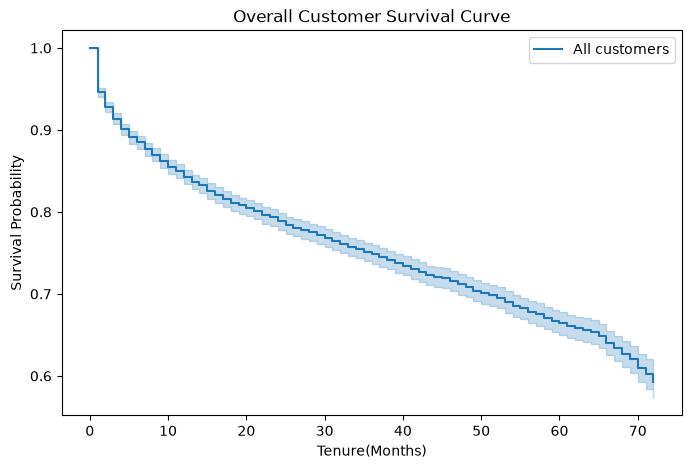

In [18]:
# How does a customer survival decline over time?

plt.figure(figsize=(8,5))
kmf = KaplanMeierFitter()
kmf.fit(durations=df['duration'],
                      event_observed = df['event'],
                      label = 'All customers')

kmf.plot_survival_function()
plt.title('Overall Customer Survival Curve')
plt.xlabel('Tenure(Months)')
plt.ylabel('Survival Probability')
plt.show()

This tells us that most of the customer churn in the starting 10 months tenure.

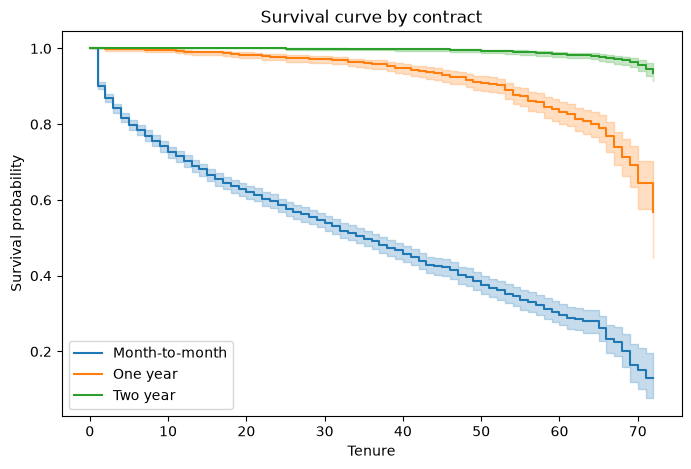

In [19]:
plt.figure(figsize=(8,5))

for contract in df['Contract'].unique():
    mask = df['Contract'] == contract
    kmf.fit(df.loc[mask, 'duration'],
            df.loc[mask, 'event'],
            label = contract)
    kmf.plot_survival_function()

plt.title('Survival curve by contract')
plt.xlabel('Tenure')
plt.ylabel('Survival probability')
plt.legend()
plt.show()

Month-to-Month customers churn significantly earlier.

In [20]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,event,duration
0,Female,0,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,1
1,Male,0,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0,34
2,Male,0,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,2
3,Male,0,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,45
4,Female,0,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,2


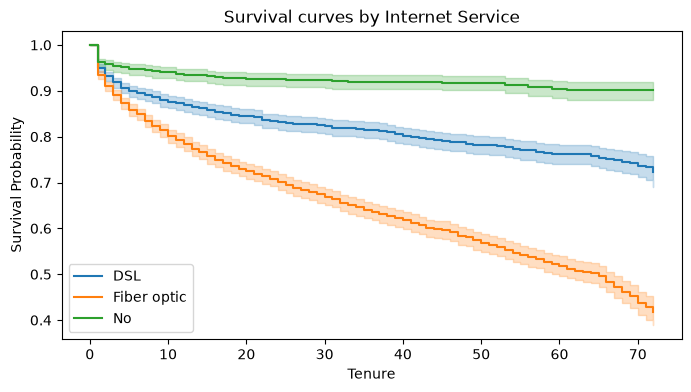

In [21]:
plt.figure(figsize=(8,4))

for method in df['InternetService'].unique():
    mask = df['InternetService'] == method
    kmf.fit(
        df.loc[mask, 'duration'],
        df.loc[mask, 'event'],
        label = method
    )
    kmf.plot_survival_function()

plt.title('Survival curves by Internet Service')
plt.xlabel('Tenure')
plt.ylabel('Survival Probability')
plt.legend()
plt.show()


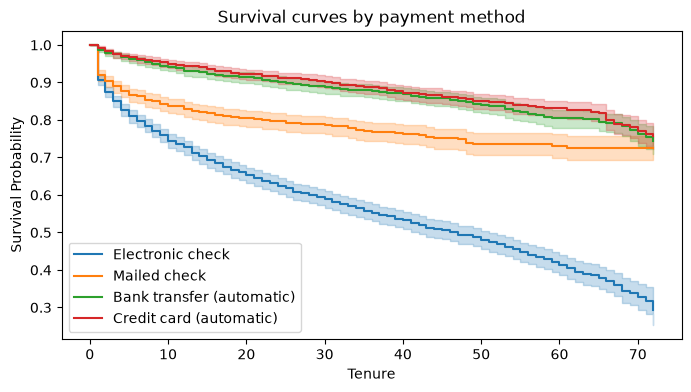

In [22]:
plt.figure(figsize=(8,4))

for method in df['PaymentMethod'].unique():
    mask = df['PaymentMethod'] == method
    kmf.fit(
        df.loc[mask, 'duration'],
        df.loc[mask, 'event'],
        label = method
    )
    kmf.plot_survival_function()

plt.title('Survival curves by payment method')
plt.xlabel('Tenure')
plt.ylabel('Survival Probability')
plt.legend()
plt.show()


Electronic check users are more likely to churn, while auto-pay users have significantly longer survival

In [23]:
df['tenure_bucket'] = pd.cut(
    df['duration'],
    bins = [0,6,12,24,48,72],
    labels = ['0-6','6-12','12-24','24-48','48+']
)

df.groupby('tenure_bucket')['event'].mean()

C:\Users\snehi\AppData\Local\Temp\ipykernel_29624\1932506218.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('tenure_bucket')['event'].mean()


tenure_bucket
0-6      0.533333
6-12     0.358865
12-24    0.287109
24-48    0.203890
48+      0.095132
Name: event, dtype: float64

0-6 months tenure has the highest probability of churn

from all this we can say:
- churn is time dependent
- Contract and payment method strongly influence churn timing
- Retention should focus on early lifecycle customers

#### Survival Modeling with Cox Proportional Hazards Model
##### The Cox Proportional Hazards Model is a widely used regression model in survival analysis that examines how different factors (covariates) affect the time until an event (like death, failure, or recovery) occurs, without requiring assumptions about the underlying event distribution.
##### It works by modeling the hazard rate (instantaneous risk of the event) as a function of covariates, assuming the effect of these factors remains constant (proportional) over time, allowing estimation of hazard ratios (HRs) that quantify the increased or decreased risk associated with each factor, such as age, gender, or treatment. 

In [24]:
cols = ['duration','event'] + [
    c for c in survival_df_enc.columns if c not in ['duration','event']
]

survival_df_enc = survival_df_enc[cols]

In [25]:
survival_df_enc.head()

,duration,event,SeniorCitizen,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,0,0,29.85,29.85,1,0,0,1,1,...,0,1,0,0,0,1,0,0,1,0
1,34,0,0,56.95,1889.50,0,1,1,0,1,...,0,0,1,0,1,0,0,0,0,1
2,2,1,0,53.85,108.15,0,1,1,0,1,...,0,1,0,0,0,1,0,0,0,1
3,45,0,0,42.30,1840.75,0,1,1,0,1,...,0,0,1,0,1,0,1,0,0,0
4,2,1,0,70.70,151.65,1,0,1,0,1,...,0,1,0,0,0,1,0,0,1,0


In [26]:
survival_df_enc.isna().sum()

duration                                   0
event                                      0
SeniorCitizen                              0
MonthlyCharges                             0
TotalCharges                               0
gender_Female                              0
gender_Male                                0
Partner_No                                 0
Partner_Yes                                0
Dependents_No                              0
Dependents_Yes                             0
PhoneService_No                            0
PhoneService_Yes                           0
MultipleLines_No                           0
MultipleLines_No phone service             0
MultipleLines_Yes                          0
InternetService_DSL                        0
InternetService_Fiber optic                0
InternetService_No                         0
OnlineSecurity_No                          0
OnlineSecurity_No internet service         0
OnlineSecurity_Yes                         0
OnlineBack

#### Train/test split

Every model score below is measured on a stratified 75/25 holdout. The split is made once and shared by all model variants, so their scores are directly comparable.

In [27]:
RANDOM_STATE = 42
PENALIZER = 0.1  # ridge penalty used for every Cox fit

train_df, test_df = train_test_split(
    survival_df_enc,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=survival_df_enc['event'],
)

print(f"train: {len(train_df):,} customers, {train_df['event'].sum():,} churn events")
print(f"test:  {len(test_df):,} customers, {test_df['event'].sum():,} churn events")

train: 5,282 customers, 1,402 churn events
test:  1,761 customers, 467 churn events


#### Model variants and the leakage check

Three versions of the Cox model are compared on the same split. Only **C** is used after this section.

| Variant | Covariates | Where it came from |
|---|---|---|
| A | every encoded column, including `TotalCharges` | the notebook's original first model |
| B | A without `TotalCharges`, plus `covariate × log(duration)` terms for the covariates that failed the proportional-hazards test | the notebook's original final model |
| C | A without `TotalCharges`, and no `log(duration)` terms | leak-free |

A and B both leak the outcome into their inputs. `TotalCharges` is roughly `MonthlyCharges × tenure`, and tenure *is* the survival duration. The `log(duration)` terms multiply covariates by the duration directly. For a customer who churned, both tell the model when they churned.

A train/test split does not catch this. The leaked value lives inside each row, so it moves into the test set along with the row.

In [28]:
# Covariates that failed the proportional-hazards test in the original notebook,
# and so received a log(duration) interaction in model B.
PH_VIOLATING_VARS = [
    'Contract_One year',
    'Contract_Two year',
    'InternetService_Fiber optic',
    'MonthlyCharges',
    'MultipleLines_Yes',
    'StreamingTV_Yes',
    'StreamingMovies_Yes',
]


def make_features(data, variant):
    """Return duration, event and the covariates for model variant 'A', 'B' or 'C'."""
    out = data.copy()
    if variant in ('B', 'C'):
        out = out.drop(columns=['TotalCharges'])
    if variant == 'B':
        # log(0) is undefined for the 11 customers with zero tenure. The original
        # notebook set those terms to 0, which is the same as using log(1).
        log_t = np.log(out['duration'].clip(lower=1))
        for var in PH_VIOLATING_VARS:
            out[f'{var}_log_time'] = out[var] * log_t
    return out


def fit_cox(data):
    model = CoxPHFitter(penalizer=PENALIZER)
    model.fit(data, duration_col='duration', event_col='event')
    return model

In [29]:
rows = []
for variant in ['A', 'B', 'C']:
    train_X = make_features(train_df, variant)
    test_X = make_features(test_df, variant)
    model = fit_cox(train_X)
    rows.append({
        'model': variant,
        'covariates': train_X.shape[1] - 2,
        'train C-index': model.concordance_index_,
        'test C-index': model.score(test_X, scoring_method='concordance_index'),
    })

model_scores = pd.DataFrame(rows).set_index('model').round(4)
model_scores

,covariates,train C-index,test C-index
model,,,
A,44,0.9044,0.8937
B,50,0.9230,0.9133
C,43,0.8638,0.8525


A and B score higher than C on both the training and the test set. That gap is the leak, not better modelling: the test set does not close it, and only removing the leaked inputs does. **C's test C-index is the honest score for this model.**

#### Final model

Model C, refit on all 7,043 customers. The holdout above was only for measuring it; everything from here on uses this fit.

In [30]:
model_df = make_features(survival_df_enc, 'C')

cph = fit_cox(model_df)
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 7043 total observations, 5174 right-censored observations>
             duration col = 'duration'
                event col = 'event'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 7043
number of events observed = 1869
   partial log-likelihood = -14161.10
         time fit was run = 2026-11-10 07:17:43 UTC

---
                                         coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                
SeniorCitizen                           -0.02      0.98      0.05           -0.11            0.08                0.89                1.08
MonthlyCharges                          -0.00      1.00      0.00           -0.00            0.00                1.00                1.00
gender_Female                            0.03      1.03      0.06           -0.08            0.14                0.92                1.15
gender_Male                             -0.03      0.97      0.06           -0.14            0.08                0.87                1.09
Partner_No                               0.23      1.25      0.06            0.11            0.34                1.12                1.41
Partner_Yes                             -0.23      0.80      0.06           -0.34           -0.11                0.71                0.89
Dependents_No                            0.07      1.07      0.06           -0.06            0.19                0.94                1.21
Dependents_Yes                          -0.07      0.94      0.06           -0.19            0.06                0.82                1.06
PhoneService_No                          0.02      1.02      0.11           -0.19            0.23                0.82                1.26
PhoneService_Yes                        -0.02      0.98      0.11           -0.23            0.19                0.79                1.21
MultipleLines_No                         0.18      1.20      0.06            0.07            0.29                1.07                1.34
MultipleLines_No phone service           0.02      1.02      0.11           -0.19            0.23                0.82                1.26
MultipleLines_Yes                       -0.19      0.82      0.06           -0.31           -0.08                0.74                0.92
InternetService_DSL                     -0.15      0.86      0.06           -0.27           -0.03                0.76                0.97
InternetService_Fiber optic              0.18      1.20      0.06            0.06            0.30                1.06                1.35
InternetService_No                      -0.06      0.94      0.09           -0.23            0.11                0.80                1.12
OnlineSecurity_No                        0.29      1.34      0.06            0.17            0.41                1.19                1.51
OnlineSecurity_No internet service      -0.06      0.94      0.09           -0.23            0.11                0.80                1.12
OnlineSecurity_Yes                      -0.31      0.73      0.06           -0.43           -0.19                0.65                0.83
OnlineBackup_No                          0.29      1.34      0.06            0.18            0.40                1.19                1.50
OnlineBackup_No internet service        -0.06      0.94      0.09           -0.23            0.11                0.80                1.12
OnlineBackup_Yes                        -0.27      0.76      0.06           -0.39           -0.16                0.68                0.86
DeviceProtection_No                      0.18      1.20      0.06            0.07            0.30                1.07                1.35
DeviceProtection_No internet service    -0.06      0.94      0.09           -0.23            0.11                0.80  

In [31]:
# Hazard ratios, exp(coef), for the covariates the Kaplan-Meier curves pointed to
cph.hazard_ratios_[[
    'InternetService_Fiber optic',
    'Contract_One year',
    'Contract_Two year',
    'PaymentMethod_Electronic check',
]].round(2)

covariate
InternetService_Fiber optic       1.20
Contract_One year                 0.71
Contract_Two year                 0.45
PaymentMethod_Electronic check    1.33
Name: exp(coef), dtype: float64

A hazard ratio above 1 means faster churn. Fiber-optic internet and electronic-check payment raise the churn hazard, and one- and two-year contracts lower it, which agrees with the Kaplan-Meier curves above.

Treat the sizes as directional only. The one-hot encoding keeps every level of each categorical (`drop_first=False`), so individual hazard ratios are not identifiable (README limitation 4).

In [32]:
# Proportional-hazards check on the final model
cph.check_assumptions(model_df, p_value_threshold=0.05)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'Contract_One year' failed the non-proportional test: p-value is <5e-05.

   Advice: with so few unique values (only 2), you can include `strata=['Contract_One year', ...]`
in the call in `.fit`. See documentation in link [E] below.

2. Variable 'Contract_Two year' failed the non-proportional test: p-value is 0.0003.

   Advice: with so few unique values (only 2), you can include `strata=['Contract_Two year', ...]`
in the call in `.fit`. See documentation in link [E] below.

3. Variable 'PaymentMethod_Mailed check' failed the non-proportional test: p-value is 0.0227.

   Advice: with so few unique values (only 2), you can include `strata=['PaymentMethod_Mailed
check', ...]` in the call in `.fit`. See documentation in link [E] below.

---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-

[]

Some covariates still fail the proportional-hazards test (README limitation 3). The original notebook tried to fix this with `covariate × log(duration)` terms, but that is model B above, which leaks the outcome. The right tools are stratification (`strata=[...]`) or a true time-varying model; both are on the roadmap.

#### Scoring active customers

Retention only applies to customers who are still active, so customers who have already churned are left out from here on.

Every risk and lifetime number below is **conditional on the tenure each customer has already completed**. Passing `conditional_after=tenure` asks the model for `S(tenure + k) / S(tenure)`: the chance of lasting another `k` months, given the customer has lasted this long.

In [33]:
active = model_df[model_df['event'] == 0]
X_active = active.drop(columns=['duration', 'event'])
tenure_active = active['duration']

print(f"Scoring {len(active):,} active customers "
      f"({len(model_df) - len(active):,} have already churned and are excluded)")

Scoring 5,174 active customers (1,869 have already churned and are excluded)


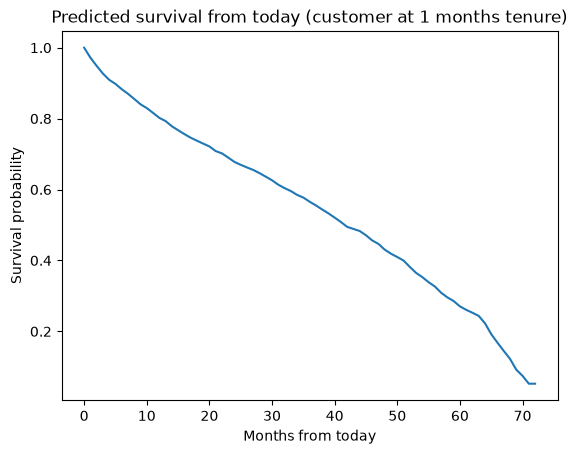

In [34]:
# Predicted survival from today onwards, for one active customer

sample_customer = X_active.iloc[[0]]
sample_tenure = tenure_active.iloc[[0]]

survival_curve = cph.predict_survival_function(sample_customer, conditional_after=sample_tenure)

ax = survival_curve.plot(legend=False,
                         title=f'Predicted survival from today (customer at {sample_tenure.iloc[0]} months tenure)')
ax.set_xlabel('Months from today')
ax.set_ylabel('Survival probability')
plt.show()

In [35]:
def churn_probability_within(model, X, months, tenure):
    """P(churn within the next `months` months | still active after `tenure` months)."""
    surv = model.predict_survival_function(X, times=[months], conditional_after=tenure)
    return 1 - surv.T.squeeze()


scored = pd.DataFrame(index=active.index)
scored['tenure'] = tenure_active
scored['MonthlyCharges'] = active['MonthlyCharges']
scored['churn_3m'] = churn_probability_within(cph, X_active, 3, tenure_active)
scored['churn_6m'] = churn_probability_within(cph, X_active, 6, tenure_active)

Each active customer now has a probability of churning in the next 3 and 6 months.

In [36]:
scored['remaining_life'] = cph.predict_expectation(X_active, conditional_after=tenure_active)

scored[['tenure', 'churn_6m', 'remaining_life']].describe()

,tenure,churn_6m,remaining_life
count,5174.000000,5174.000000,5174.000000
mean,37.569965,0.066657,52.351092
std,24.113777,0.082558,16.955050
min,0.000000,0.000000,5.795257
25%,15.000000,0.013135,39.096931
50%,38.000000,0.036882,57.895437
75%,61.000000,0.088135,66.738108
max,72.000000,0.943914,72.000000


**Data horizon caveat.** Tenure in this dataset stops at 72 months, so the model has no information about churn after month 72, and lifelines holds the hazard flat past that point. Two consequences:

- `remaining_life` integrates the survival curve over the next 72 months only. It is a capped (restricted) mean, not an unbounded expected lifetime.
- When a customer's 3- or 6-month window runs past month 72, the part beyond 72 contributes no churn risk, so their churn probability is understated. A customer at exactly 72 months gets 0.

In [37]:
past_horizon = scored['tenure'] > 72 - 6
print(f"{past_horizon.sum():,} of {len(scored):,} active customers have a 6-month window that runs past month 72")

894 of 5,174 active customers have a 6-month window that runs past month 72


#### Customer lifetime value

CLV ~ Monthly revenue X Expected remaining lifetime

In [38]:
scored['CLV'] = scored['MonthlyCharges'] * scored['remaining_life']

In [39]:
scored['CLV'].describe()

count    5174.000000
mean     3148.385041
std      2062.119347
min       367.189452
25%      1347.366599
50%      2460.058417
75%      4655.617423
max      8550.000000
Name: CLV, dtype: float64

<Axes: ylabel='Frequency'>

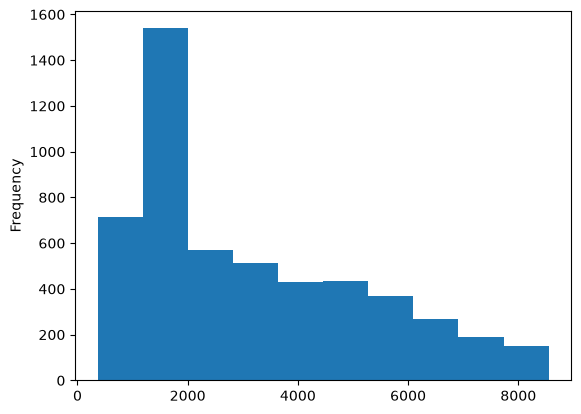

In [40]:
scored['CLV'].plot(kind = 'hist')

In [41]:
scored['CLV_segment'] = pd.qcut(
    scored['CLV'],
        q = [0,0.5,0.8,1.0],
        labels = ['Low','Medium','High']
)

In [42]:
scored["risk_segment"] = pd.qcut(
    scored["churn_6m"],
    q=[0, 0.7, 0.9, 1.0],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

In [43]:
def retention_action(row):
    if row["CLV_segment"] == "High" and row["risk_segment"] == "High Risk":
        return "Immediate Retention"
    if row["CLV_segment"] == "High" and row["risk_segment"] == "Low Risk":
        return "Monitor"
    if row["CLV_segment"] == "Low" and row["risk_segment"] == "High Risk":
        return "No Action"
    return "Ignore"

scored["action"] = scored.apply(retention_action, axis=1)

#### Visualization

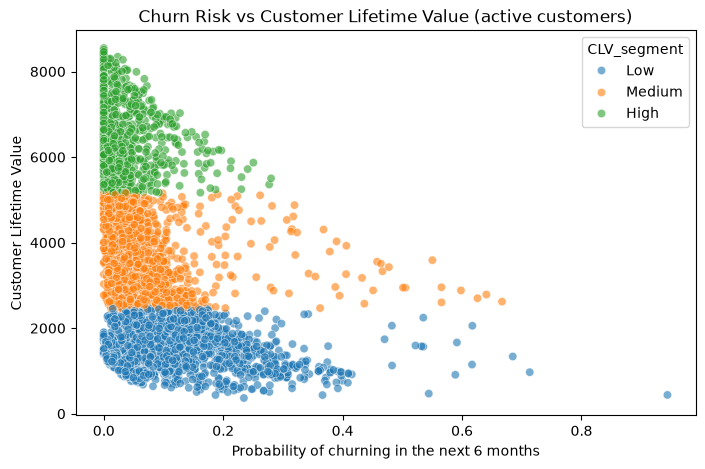

In [44]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=scored,
    x="churn_6m",
    y="CLV",
    hue="CLV_segment",
    alpha=0.6
)
plt.title("Churn Risk vs Customer Lifetime Value (active customers)")
plt.xlabel("Probability of churning in the next 6 months")
plt.ylabel("Customer Lifetime Value")
plt.show()

##### So, who should we spend money on to prevent churn? (profit maximization)

#### Core formula:

` Expected value = (CLV X Retention success probability) - Retention cost`

only intervene if:
`Expected value > 0`

In [45]:
#assumptions

Retention_cost = 500

def retention_probability(risk_segment):
    if risk_segment == 'High Risk':
        return 0.4
    elif risk_segment == 'Medium Risk':
        return 0.25
    else:
        return 0.1

In [46]:
scored['retention_success_prob'] = scored['risk_segment'].apply(retention_probability).astype(float)

In [47]:
# Expected value

scored['expected_retention_value'] = (scored['CLV'] * scored['retention_success_prob'])

In [48]:
scored['net_value'] = (scored['expected_retention_value'] - Retention_cost)

In [49]:
scored.sort_values(by = 'net_value', ascending= False).head(10)

,tenure,MonthlyCharges,churn_3m,churn_6m,remaining_life,CLV,CLV_segment,risk_segment,action,retention_success_prob,expected_retention_value,net_value
6112,66,104.90,0.071519,0.192514,58.800303,6168.151756,High,High Risk,Immediate Retention,0.4,2467.260702,1967.260702
2079,70,106.05,0.196866,0.196866,58.042692,6155.427506,High,High Risk,Immediate Retention,0.4,2462.171002,1962.171002
6180,66,102.40,0.064326,0.174357,60.047075,6148.820446,High,High Risk,Immediate Retention,0.4,2459.528178,1959.528178
1435,65,109.40,0.076610,0.183246,56.027243,6129.380423,High,High Risk,Immediate Retention,0.4,2451.752169,1951.752169
3606,70,101.75,0.171857,0.171857,59.816343,6086.312860,High,High Risk,Immediate Retention,0.4,2434.525144,1934.525144
617,66,102.85,0.079791,0.213072,57.388195,5902.375824,High,High Risk,Immediate Retention,0.4,2360.950329,1860.950329
4447,68,107.70,0.171635,0.250489,54.502213,5869.888364,High,High Risk,Immediate Retention,0.4,2347.955346,1847.955346
5904,70,98.90,0.178903,0.178903,59.316656,5866.417263,High,High Risk,Immediate Retention,0.4,2346.566905,1846.566905
3453,70,97.65,0.171958,0.171958,59.809192,5840.367599,High,High Risk,Immediate Retention,0.4,2336.147040,1836.147040
4566,68,100.30,0.144161,0.212091,57.187699,5735.926237,High,High Risk,Immediate Retention,0.4,2294.370495,1794.370495


In [50]:
scored['retain_decision'] = np.where(
    scored['net_value'] > 0,
    'Target for retention',
    'Do not target'
)

In [51]:
scored['retain_decision'].value_counts()

retain_decision
Do not target           3246
Target for retention    1928
Name: count, dtype: int64

##### let's compare risk based and expected value based retention strategies

In [52]:
top_risk_cutoff = scored["churn_6m"].quantile(0.85)

scored["risk_based_target"] = np.where(
    scored["churn_6m"] >= top_risk_cutoff,
    "Target",
    "No Target"
)

In [53]:
# risk based

risk_profit = scored.loc[scored['risk_based_target'] == 'Target', 'net_value'].sum()

In [54]:
# Expected value based

exp_value_based_profit = scored.loc[scored['retain_decision']== 'Target for retention','net_value'].sum()

In [55]:
print("Risk-based strategy profit:", risk_profit)
print("Profit-based strategy profit:", exp_value_based_profit)

Risk-based strategy profit: 129547.74425329949
Profit-based strategy profit: 505154.98335725715


**Caveat: this comparison is circular.** The profit-based strategy is defined as "everyone with `net_value > 0`" and then scored by summing `net_value`, so it cannot lose. The two strategies also target different numbers of customers. A fair test compares both on a holdout at the same budget (README limitation 2).

In [56]:
scored.groupby("retain_decision").agg(
    customers=("CLV", "count"),
    avg_clv=("CLV", "mean"),
    avg_net_value=("net_value", "mean")
)

,customers,avg_clv,avg_net_value
retain_decision,,,
Do not target,3246,2172.986517,-238.395793
Target for retention,1928,4790.575709,262.009846
